In [28]:
import os
from pathlib import Path

RAIZ = Path.home() / "master-data-ia"
os.chdir(RAIZ)
print(Path.cwd())

/Users/alvaroocrespoo/master-data-ia


In [8]:
import pandas as pd

leido = pd.read_parquet(carpeta / "fact_ventas.parquet")
print(leido.shape)
print(leido.dtypes.head(6))
desde_csv = pd.read_csv(carpeta / "fact_ventas.csv")
print(desde_csv.dtypes.head(6))

(366928, 14)
pedido_id        int64
num_linea        int64
fecha_key        int32
cliente_key      int32
producto_key     int32
comercial_key    int32
dtype: object
pedido_id        int64
num_linea        int64
fecha_key        int64
cliente_key      int64
producto_key     int64
comercial_key    int64
dtype: object


In [10]:
import duckdb
con = duckdb.connect("../db/marejada.duckdb", read_only=True)
productos = con.sql("SELECT * FROM gold.dim_producto WHERE producto_key > 0").df()
con.close()
#----------------------------
print(productos.shape)
productos.dtypes

(235, 13)


producto_key        int32
producto_id         int64
sku                   str
nombre                str
categoria             str
subcategoria          str
marca                 str
formato               str
precio_lista      float64
coste_unitario    float64
iva_pct             int64
activo               bool
gama_precio           str
dtype: object

In [35]:
import pandas as pd
comerciales = pd.read_csv("datos/rrhh/comerciales.csv", encoding="latin-1")
comerciales[["comercial_id", "nombre", "apellidos", "jefe_id"]].head(4)

,comercial_id,nombre,apellidos,jefe_id
0,1,Íñigo,Sainz Ruiz,NaN
1,2,Raquel,Fernández Cobo,1.0
2,3,Daniel,Gutiérrez Pérez,2.0
3,4,Sara,Ceballos Ortiz,2.0


In [36]:
comerciales["jefe_id"] = comerciales["jefe_id"].astype("Int64")
comerciales["jefe_id"].head(4)

0    <NA>
1       1
2       2
3       2
Name: jefe_id, dtype: Int64

In [37]:
import pandas as pd
conta = pd.read_excel("datos/contabilidad/facturacion_mensual_2024-2026.xlsx", skiprows=3)
print(conta.shape)
conta.head()

(151, 5)


,Año,Mes,Provincia,Base imponible (€),Gastos de envío incluidos (€)
0,2024,enero,Asturias,206720.18,774
1,2024,enero,Burgos,76489.34,612
2,2024,enero,Cantabria,474353.90,2064
3,2024,enero,Palencia,53726.63,180
4,2024,febrero,Asturias,152919.36,1008


In [39]:
import json
with open("datos/web/pedidos_web.json", encoding="utf-8") as f:
    web = json.load(f)
pedidos_web = pd.json_normalize(web["orders"])
print(pedidos_web.shape)
pedidos_web.drop(columns="items").head(3)

(7956, 8)


,order_id,created_at,shipping,status,erp_pedido_id,customer.nif,customer.name
0,WEB-000001,2025-04-07T04:04:00Z,0.0,completed,2.025006e+09,B43996889,Bar La Castellana
1,WEB-000002,2025-04-07T15:00:00Z,0.0,completed,2.025006e+09,B45715312,Restaurante La Pradera
2,WEB-000003,2025-04-07T16:39:00Z,0.0,completed,2.025006e+09,B41082697,Catering La Barquera


In [43]:
web_cancelados = pedidos[(pedidos['canal']=='Web B2B') & (pedidos['estado'] == 'Cancelado')]
len(web_cancelados)

297

In [40]:
lineas_web = pd.json_normalize(
    web["orders"],
    record_path="items",
    meta=["order_id", "erp_pedido_id", "status"],
)
print(lineas_web.shape)
lineas_web.head(3)

(38825, 7)


,sku,qty,unit_price,discount,order_id,erp_pedido_id,status
0,AGU-0014,1,9.13,5.0,WEB-000001,2025005606,completed
1,CER-0071,2,70.16,5.0,WEB-000001,2025005606,completed
2,LIM-0007,10,15.24,5.0,WEB-000001,2025005606,completed


In [32]:
import pandas as pd
pedidos = pd.read_csv(
    "datos/erp/pedidos.csv",
    sep=";",
    decimal=",",
    parse_dates=["fecha_pedido", "fecha_entrega"],
    date_format={"fecha_pedido": "%d/%m/%Y %H:%M", "fecha_entrega": "%d/%m/%Y"},
)
print(pedidos.shape)
pedidos.dtypes

(77448, 10)


pedido_id                 int64
fecha_pedido     datetime64[us]
cliente_id                int64
comercial_id              int64
canal                       str
estado                      str
fecha_entrega    datetime64[us]
almacen                     str
gastos_envio            float64
observaciones               str
dtype: object

In [6]:
from pathlib import Path
import duckdb
con = duckdb.connect("../db/marejada.duckdb", read_only=True)
ventas = con.sql("SELECT * FROM gold.fact_ventas").df()
con.close()
carpeta = Path("../datos/exportaciones")
carpeta.mkdir(exist_ok=True)
ventas.to_parquet(carpeta / "fact_ventas.parquet", index=False)
ventas.to_csv(carpeta / "fact_ventas.csv", index=False)
for f in sorted(carpeta.glob("fact_ventas.*")):
    print(f.name, round(f.stat().st_size / 1024 / 1024, 1), "MB")

fact_ventas.csv 29.8 MB
fact_ventas.parquet 4.8 MB


In [22]:
categorias = productos['categoria']
print(type(categorias))
categorias.value_counts()


categoria
Cervezas                84
Refrescos               26
Vinos                   26
Licores y destilados    23
Alimentación            18
Limpieza e higiene      18
Café e infusiones       17
Aguas                   15
Desechables              8
Name: count, dtype: int64

In [23]:
precios = productos['precio_lista']
print(precios.mean().round(2), precios.max())
(precios * 1.21).head(3)

32.29 117.77


0    123.4200
1     85.5107
2     25.3374
Name: precio_lista, dtype: float64

In [18]:
import duckdb
con = duckdb.connect("../db/marejada.duckdb", read_only=True)
productos = con.sql("SELECT * FROM gold.dim_producto WHERE producto_key > 0").df()
con.close()
#----------------------------
productos[['activo', 'marca']].describe()

,activo,marca
count,235,235
unique,2,36
top,True,Faro Norte
freq,211,19


In [9]:
import duckdb
con = duckdb.connect("../db/marejada.duckdb", read_only=True)
productos = con.sql("SELECT * FROM gold.dim_producto WHERE producto_key > 0").df()
con.close()

print(productos.columns.tolist())


['producto_key', 'producto_id', 'sku', 'nombre', 'categoria', 'subcategoria', 'marca', 'formato', 'precio_lista', 'coste_unitario', 'iva_pct', 'activo', 'gama_precio']


In [3]:
import duckdb
con = duckdb.connect("../db/marejada.duckdb", read_only=True)
productos = con.sql("SELECT * FROM gold.dim_producto WHERE producto_key > 0").df()
con.close()

productos.head()

,producto_key,producto_id,sku,nombre,categoria,subcategoria,marca,formato,precio_lista,coste_unitario,iva_pct,activo,gama_precio
0,1,1001,CER-0001,Faro Norte Lager,Cervezas,Lager,Faro Norte,Barril 30 L,102.00,70.33,21,False,3. Premium
1,2,1002,CER-0002,Faro Norte Lager,Cervezas,Lager,Faro Norte,Barril 20 L,70.67,51.75,21,True,3. Premium
2,3,1003,CER-0003,Faro Norte Lager,Cervezas,Lager,Faro Norte,Caja 24x33 cl lata,20.94,14.58,21,False,2. Gama media
3,4,1004,CER-0004,Faro Norte Lager,Cervezas,Lager,Faro Norte,Caja 12x75 cl,19.20,14.20,21,True,2. Gama media
4,5,1005,CER-0005,Faro Norte Especial,Cervezas,Especial,Faro Norte,Barril 30 L,117.77,79.49,21,True,3. Premium


In [1]:
import pandas as pd
import duckdb

pd.__version__

'3.0.6'

In [9]:
dos = pd.read_parquet(carpeta / "fact_ventas.parquet", columns=["fecha_key", "importe_neto"])
dos.shape

(366928, 2)

In [10]:
duckdb.sql("""
SELECT count(*) AS lineas, round(sum(importe_neto), 2) AS ventas
FROM '../datos/exportaciones/fact_ventas.parquet'
""")

┌────────┬─────────────┐
│ lineas │   ventas    │
│ int64  │   double    │
├────────┼─────────────┤
│ 366928 │ 42633273.34 │
└────────┴─────────────┘

In [11]:
import requests
r = requests.get(
"https://api.frankfurter.dev/v1/latest",
params={"base": "EUR", "symbols": "GBP"},
timeout=10,
)
print(r.status_code)
print(r.url)
r.json()

200
https://api.frankfurter.dev/v1/latest?base=EUR&symbols=GBP


{'amount': 1.0, 'base': 'EUR', 'date': '2026-11-06', 'rates': {'GBP': 0.83415}}

In [12]:
r = requests.get(
"https://api.frankfurter.dev/v1/2025-01-01..2025-01-10",
params={"base": "EUR", "symbols": "GBP"},
timeout=10,
)
r.raise_for_status()
datos = r.json()
print(datos["start_date"], datos["end_date"])
datos["rates"]

2024-12-31 2025-01-10


{'2024-12-31': {'GBP': 0.82918},
 '2025-01-02': {'GBP': 0.83118},
 '2025-01-03': {'GBP': 0.82993},
 '2025-01-06': {'GBP': 0.83098},
 '2025-01-07': {'GBP': 0.82915},
 '2025-01-08': {'GBP': 0.83403},
 '2025-01-09': {'GBP': 0.83808},
 '2025-01-10': {'GBP': 0.83693}}

In [13]:
import time
def tipos_de_cambio(anio, moneda="GBP"):
    """Serie diaria EUR -> moneda de un año completo, solo con fechas de ese año."""
    r = requests.get(
        f"https://api.frankfurter.dev/v1/{anio}-01-01..{anio}-12-31",
        params={"base": "EUR", "symbols": moneda},
        timeout=10,
    )
    r.raise_for_status()
    serie = pd.Series({f: t[moneda] for f, t in r.json()["rates"].items()}, name=moneda)
    serie.index = pd.to_datetime(serie.index)
    return serie[serie.index.year == anio]

tramos = []
for anio in [2024, 2025]:
    tramos.append(tipos_de_cambio(anio))
    time.sleep(1)
    
gbp = pd.concat(tramos)
print(len(gbp), gbp.index.min().date(), gbp.index.max().date())

511 2024-01-02 2025-12-31


In [14]:
def tipos_con_cache(anio, moneda="GBP"):
    fichero = carpeta / f"tipos_{moneda}_{anio}.csv"
    if fichero.exists():
        print("desde la caché:", fichero.name)
        return pd.read_csv(fichero, index_col=0, parse_dates=True).squeeze("columns")
    print("pidiendo a la API:", anio)
    serie = tipos_de_cambio(anio, moneda)
    serie.to_csv(fichero)
    return serie

a = tipos_con_cache(2025)
b = tipos_con_cache(2025)
print(len(a), len(b), (a == b).all())

pidiendo a la API: 2025
desde la caché: tipos_GBP_2025.csv
255 255 True


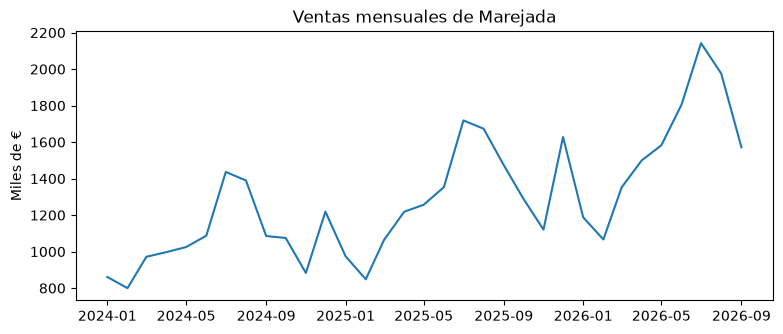

In [16]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 3.5))
mensual = (
    ventas.assign(fecha=pd.to_datetime(ventas["fecha_key"].astype(str), format="%Y%m%d"))
    .set_index("fecha")["importe_neto"]
    .resample("MS")
    .sum()
)
ax.plot(mensual.index, mensual / 1000)
ax.set_title("Ventas mensuales de Marejada")
ax.set_ylabel("Miles de €")
plt.show()

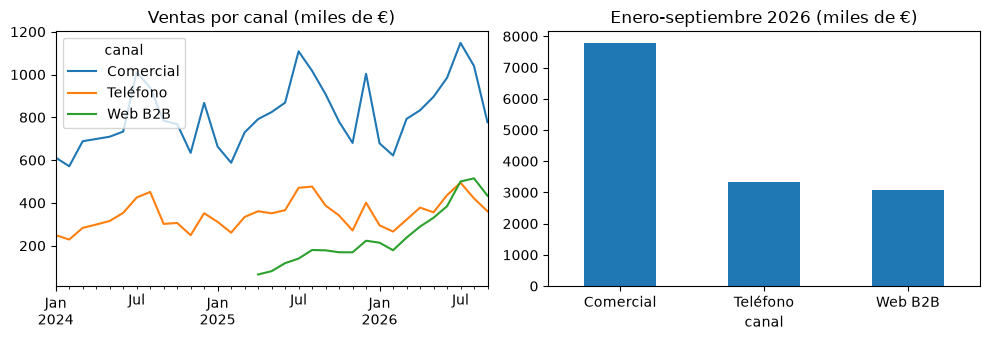

In [17]:
con = duckdb.connect("../db/marejada.duckdb", read_only=True)
por_canal = con.sql("""
    SELECT d.inicio_mes AS mes, f.canal, sum(f.importe_neto) / 1000 AS miles
    FROM gold.fact_ventas AS f
    JOIN gold.dim_fecha AS d ON d.fecha_key = f.fecha_key
    GROUP BY ALL
""").df()
con.close()
ancho = por_canal.pivot_table(index="mes", columns="canal", values="miles")
fig, (izq, der) = plt.subplots(1, 2, figsize=(10, 3.5))
ancho.plot(ax=izq, title="Ventas por canal (miles de €)")
ancho.loc["2026"].sum().plot.bar(ax=der, title="Enero-septiembre 2026 (miles de €)", rot=0)
izq.set_xlabel("")
plt.tight_layout()
plt.show()

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(mensual.index, mensual / 1000, color="#1f4e79")
ax.set_title("Ventas mensuales de Marejada (miles de €)")
ax.grid(alpha=0.3)
fig.savefig("../entregables/ventas_mensuales.png", dpi=150, bbox_inches="tight")
plt.close(fig)
Path("../entregables/ventas_mensuales.png").exists()

True